# Escalamiento final de Misión conexiones: N=10…14

Este notebook acompaña la campaña final y lee sus mediciones guardadas. Compara costo, brecha al óptimo, aciertos, tiempo y memoria. No vuelve a ejecutar QAOA.

**Procedencia:** QAP10 original en N=10. N=11…14 son extensiones sintéticas anidadas que mantienen el bloque 10×10 y usan semilla de datos 20261025. Flujos y distancias son pesos del modelo, no pasajeros ni metros medidos.

**Reproducción:** desde la raíz del repo, `pip install -r requirements.txt` y `python scaling14_study.py`. Para abrir este notebook: `pip install jupyterlab ipykernel`. Los resultados individuales están en `results/scaling14_jobs/`; la explicación está en `docs/scaling14_results.md`.

El notebook exploratorio anterior se conserva por separado en `qap10_track_a_analysis.ipynb`.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

root = Path.cwd()
if not (root / 'results/scaling14.json').exists():
    root = root.parent
path = root / 'results/scaling14.json'
assert path.exists(), 'Ejecuta este notebook dentro del repositorio.'
study = json.loads(path.read_text(encoding='utf-8'))
assert study['complete'], 'Termina primero python scaling14_study.py.'
summary = pd.DataFrame(study['summary'])
references = pd.DataFrame(study['rows'])
q14 = summary.query("n == 14 and method == 'qaoa'").iloc[0]
display(Markdown(f"**N=14: óptimo certificado {int(references.query('n == 14').iloc[0]['optimum'])}. "
                 f"QAOA: mejor {q14.best_cost:g}, mediana {q14.median_cost:g}, "
                 f"brecha mediana {q14.median_gap_percent:.2f}%, "
                 f"aciertos {q14.optimal_hits}/{q14.runs}.**"))
print('Jobs completos:', study['jobs_completed'], '/', study['jobs_expected'])
print('Hash de fuentes:', study['solver_source_sha256'])

**N=14: óptimo certificado 728. QAOA: mejor 794, mediana 830, brecha mediana 14.01%, aciertos 0/5.**

Jobs completos: 106 / 106
Hash de fuentes: 6dea059ae5020af2ed357ccad230a4630882118bf319af9fd92e825003a546be


## Método y presupuesto

Cinco semillas por tamaño y método. Los tres LNS comparten asignación inicial, vuelos liberados y presupuesto de 60 iteraciones, con K=3, p=2, hasta 60 evaluaciones COBYLA y 512 shots. El exacto global nunca proporciona el inicio de la búsqueda híbrida.

El entrenamiento simula clásicamente el mismo circuito en sus seis permutaciones factibles. **Cada llamada** verifica la distribución con el circuito completo de nueve qubits en Aer y muestrea con SamplerV2. El QUBO completo de 196 qubits no se simula. La ejecución usa procesos separados, secuenciales y los mismos controles de hilos.

Los tiempos incluyen el solver y su validación, sin imports ni escritura de archivos. RSS es memoria del proceso, incluidas librerías, con intervalo de muestreo solicitado de 5 ms: puede omitir picos breves. El presupuesto es de iteraciones, no de tiempo igualado. El criterio de parada de FAQ es propio del método.

## Referencias globales

Ramificación y poda con cota Gilmore–Lawler y asignación lineal de SciPy. La búsqueda completa certifica el mínimo y cuenta los óptimos. En N=10 se coteja también con enumeración. Las pruebas pequeñas verifican costo y conteos contra enumeración independiente.

In [2]:
ref_table = references[['n', 'optimum', 'reference_lower_bound', 'optimal_assignments',
                        'exact_seconds', 'exact_peak_rss_bytes']].copy()
ref_table['exact_peak_rss_bytes'] /= 2**20
ref_table.columns = ['N', 'Óptimo', 'Cota final', 'Número de óptimos', 'Tiempo (s)', 'RSS pico (MiB)']
display(ref_table.round(4))
assert all(r['certified'] and r['lower_bound'] == r['optimum']
           for r in study['references'].values())
assert references.query('n == 10').iloc[0]['optimum'] == 340

,N,Óptimo,Cota final,Número de óptimos,Tiempo (s),RSS pico (MiB)
0,10,340,340,1,0.0339,105.8125
1,11,418,418,1,0.0871,106.6562
2,12,530,530,4,0.7699,107.9688
3,13,638,638,1,1.4971,110.4102
4,14,728,728,1,6.3164,113.2812


## Comparación de las cinco semillas

Menor costo y menor brecha son mejores. La columna de aciertos muestra cuántas semillas alcanzaron la referencia global. El tiempo y la memoria son mediciones de la campaña nueva, sin mezclar tiempos históricos.

In [3]:
labels = {'exact':'LNS + exacto', 'qaoa':'LNS + QAOA',
          'random':'LNS + azar', 'scipy_faq':'SciPy FAQ'}
table = summary[['n', 'method', 'median_cost', 'best_cost', 'median_gap_percent',
                 'optimal_hits', 'runs', 'median_seconds', 'median_peak_rss_bytes']].copy()
table['method'] = table['method'].map(labels)
table['optimal_hits'] = table['optimal_hits'].astype(str) + '/' + table['runs'].astype(str)
table = table.drop(columns='runs')
table['median_peak_rss_bytes'] /= 2**20
table.columns = ['N', 'Método', 'Mediana', 'Mejor', 'Brecha mediana (%)',
                 'Aciertos óptimos', 'Tiempo mediano (s)', 'RSS mediana (MiB)']
display(table.round(4))
assert summary.all_feasible.all()

,N,Método,Mediana,Mejor,Brecha mediana (%),Aciertos óptimos,Tiempo mediano (s),RSS mediana (MiB)
0,10,LNS + exacto,374,372,10.0000,0/5,0.0078,105.8906
1,10,LNS + azar,422,404,24.1176,0/5,0.0073,105.8711
2,10,SciPy FAQ,380,364,11.7647,0/5,0.0013,105.6758
3,10,LNS + QAOA,374,360,10.0000,0/5,41.7085,118.6953
4,11,LNS + exacto,460,426,10.0478,0/5,0.0089,105.7383
5,11,LNS + azar,492,480,17.7033,0/5,0.0079,106.0039
6,11,SciPy FAQ,462,426,10.5263,0/5,0.0014,105.8086
7,11,LNS + QAOA,454,426,8.6124,0/5,45.1587,118.6758
8,12,LNS + exacto,564,548,6.4151,0/5,0.0096,105.8672
9,12,LNS + azar,606,566,14.3396,0/5,0.0084,105.9258


## Calidad, tiempo y memoria al crecer N

Cada punto resume cinco semillas. Las líneas unen tamaños de una misma familia sintética y no representan una ley universal de escalamiento. La escala del tiempo es logarítmica. RSS incluye la base de Python y librerías.

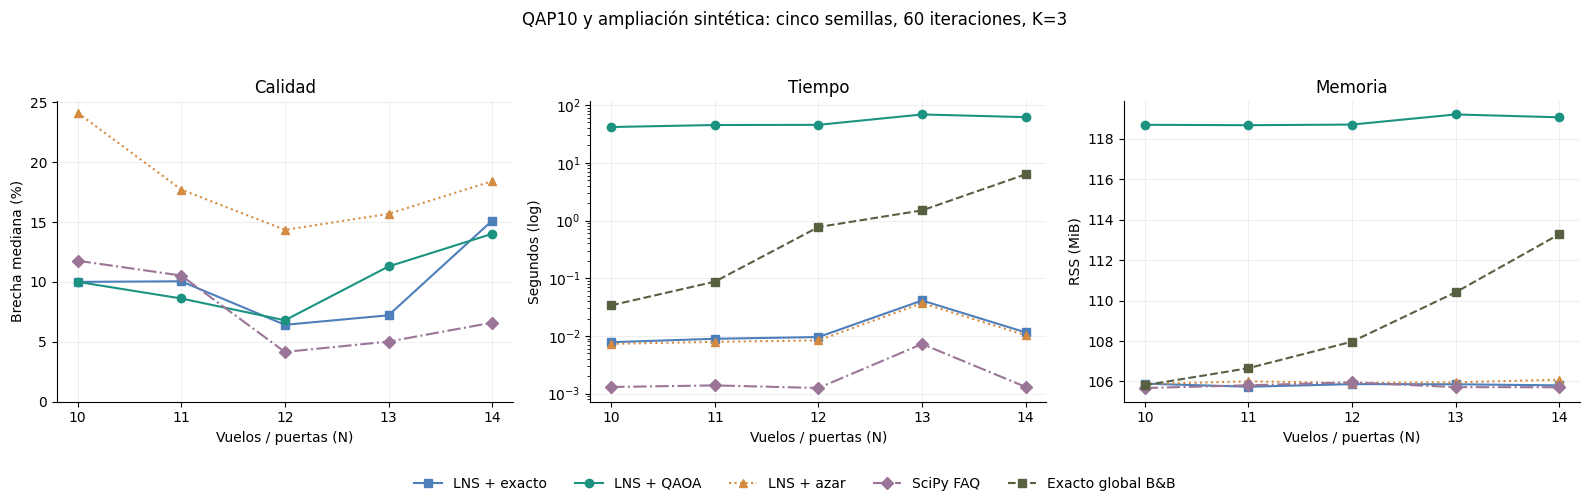

In [4]:
colors = {'exact':'#4d7fbb', 'qaoa':'#1b9380', 'random':'#d48b40', 'scipy_faq':'#9a7597'}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for method, label in labels.items():
    group = summary.query('method == @method').sort_values('n')
    for ax, metric, divisor in zip(axes,
            ['median_gap_percent', 'median_seconds', 'median_peak_rss_bytes'], [1, 1, 2**20]):
        ax.plot(group.n, group[metric]/divisor, label=label, color=colors[method],
                marker={'exact':'s', 'qaoa':'o', 'random':'^', 'scipy_faq':'D'}[method],
                linestyle={'exact':'-', 'qaoa':'-', 'random':':', 'scipy_faq':'-.'}[method])
axes[1].plot(references.n, references.exact_seconds, 's--', color='#576041', label='Exacto global B&B')
axes[2].plot(references.n, references.exact_peak_rss_bytes/2**20, 's--', color='#576041', label='Exacto global B&B')
for ax, title, unit in zip(axes, ['Calidad', 'Tiempo', 'Memoria'],
                        ['Brecha mediana (%)', 'Segundos (log)', 'RSS (MiB)']):
    ax.set_title(title)
    ax.set_xlabel('Vuelos / puertas (N)')
    ax.set_ylabel(unit)
    ax.set_xticks(range(10, 15))
    ax.grid(alpha=.2)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylim(bottom=0)
axes[1].set_yscale('log')
handles, names = axes[1].get_legend_handles_labels()
fig.legend(handles, names, loc='lower center', ncol=5, frameon=False)
fig.suptitle('QAP10 y ampliación sintética: cinco semillas, 60 iteraciones, K=3')
fig.tight_layout(rect=(0, .08, 1, .94))
plt.show()

## Verificación del componente Qiskit y lectura del resultado

Encontrar el óptimo de un vecindario de tres vuelos no garantiza la mejor asignación de catorce vuelos. Se mide la calidad global por separado. Preservar factibilidad tampoco demuestra una ventaja cuántica en costo o tiempo. Cinco semillas de una sola familia de instancias permiten una comparación exploratoria.

In [5]:
calls = [e['qaoa'] for run in study['lns_runs'] if run['subsolver'] == 'qaoa'
         for e in run['events']]
max_error = max(call['subspace_verification_max_probability_error'] for call in calls)
assert len(calls) == 1500
assert max_error < 1e-8
assert all(call['qubits'] == 9 for call in calls)
print('Llamadas con verificación del circuito completo y muestreo Qiskit:', len(calls))
print('Mayor diferencia de probabilidad entre subespacio y Aer:', f'{max_error:.3e}')
print('Qubits por llamada:', 9)
for n in range(10, 15):
    row = summary.query("n == @n and method == 'qaoa'").iloc[0]
    optimum = int(references.query('n == @n').iloc[0]['optimum'])
    print(f'N={n}: óptimo {optimum}; QAOA mejor {row.best_cost:g}, '
          f'mediana {row.median_cost:g}, aciertos {row.optimal_hits}/{row.runs}.')

Llamadas con verificación del circuito completo y muestreo Qiskit: 1500
Mayor diferencia de probabilidad entre subespacio y Aer: 6.517e-09
Qubits por llamada: 9
N=10: óptimo 340; QAOA mejor 360, mediana 374, aciertos 0/5.
N=11: óptimo 418; QAOA mejor 426, mediana 454, aciertos 0/5.
N=12: óptimo 530; QAOA mejor 540, mediana 566, aciertos 0/5.
N=13: óptimo 638; QAOA mejor 688, mediana 710, aciertos 0/5.
N=14: óptimo 728; QAOA mejor 794, mediana 830, aciertos 0/5.


## Demo y fuentes

En la app, selecciona N=14 y una semilla. Reproduce el cálculo, abre «Óptimo exacto» y compara «Óptimo → resultado QAOA». En «Todos los flujos», la distancia acumulada al finalizar coincide con el costo del modelo. Los segundos de caminata son ilustrativos.

Fuentes: `results/scaling14.json`, los jobs individuales, `src/qap/exact_bound.py`, `src/qap/qaoa.py` y `docs/scaling14_results.md`.

Referencias metodológicas: [Lawler, 1963](https://doi.org/10.1287/mnsc.9.4.586), [asignación lineal SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html), [FAQ y 2-opt](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.quadratic_assignment.html).